# LAB 13 — Artificial Neural Networks: The Multi-Layer Perceptron
## Student Information
- **Name:** Muhammad Taraz
- **CMS ID:** 023-24-0259
- **Section:** H
- **Date:** 24 Nov 2026

**Dataset:** XOR and Breast Cancer Wisconsin (built into scikit-learn)

*The PDF calls this ML Lab 12, while the original notebook template title says Lab 13. The provided template is kept and filled in.*


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([0, 1, 1, 0])
print("Ready. TensorFlow", tf.__version__)


I0000 00:00:1795465887.195704   40101 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795465889.107592   40101 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Ready. TensorFlow 2.21.0


## Part 0 — Key Concepts
- **MLP:** A neural network made of an input layer, hidden layer(s), and output layer.
- **Hidden layer:** A layer between input and output that learns useful patterns.
- **Activation function:** Adds non-linearity so a network can learn more than straight-line patterns.
- **Sigmoid:** Maps a number to a value between 0 and 1.
- **Loss:** Measures how far predictions are from correct answers.
- **Gradient descent:** Updates weights in the direction that reduces loss.
- **Backpropagation:** Uses the chain rule to calculate gradients from output back toward input.


## Part 1 — Why We Need Non-Linear Activations

### 1.1 Activation Functions and Their Slopes
**Task 1.1**: Plot step and sigmoid with their derivatives in a 2 by 2 grid, and print each maximum derivative.

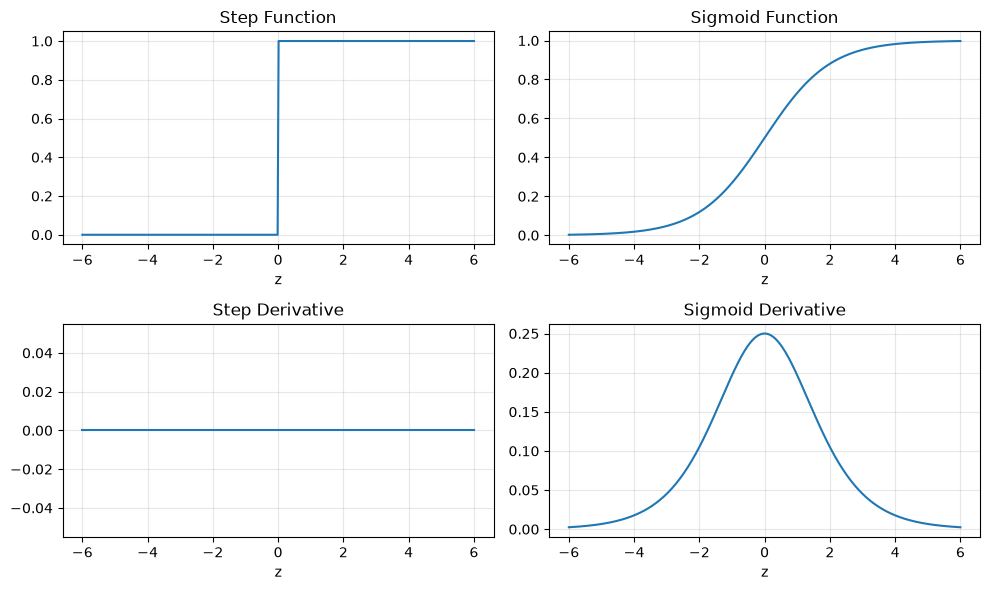

Maximum step derivative (away from threshold): 0.0
Maximum sigmoid derivative: 0.2499858674555797


In [2]:
# Task 1.1
def step(z):
    return np.where(np.asarray(z) >= 0, 1.0, 0.0)

def step_derivative(z):
    # The derivative is zero except at the threshold, where it is undefined.
    return np.zeros_like(np.asarray(z), dtype=float)

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

z = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(z, step(z))
axes[0, 0].set_title("Step Function")
axes[0, 1].plot(z, sigmoid(z))
axes[0, 1].set_title("Sigmoid Function")
axes[1, 0].plot(z, step_derivative(z))
axes[1, 0].set_title("Step Derivative")
axes[1, 1].plot(z, sigmoid_derivative(z))
axes[1, 1].set_title("Sigmoid Derivative")
for ax in axes.flat:
    ax.set_xlabel("z")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Maximum step derivative (away from threshold):", step_derivative(z).max())
print("Maximum sigmoid derivative:", sigmoid_derivative(z).max())


**Interpretation:** The step function has a zero derivative almost everywhere, so it gives gradient descent no useful direction for updating weights. Sigmoid is smooth and its derivative reaches about 0.25 near zero, which lets the network adjust its weights.

### 1.2 Stacking Linear Layers Collapses
**Task 1.2**: Verify two linear layers can be combined into one, then repeat with sigmoid between layers.

In [3]:
# Task 1.2
np.random.seed(42)
W1 = np.random.randn(2, 3)
b1 = np.random.randn(3)
W2 = np.random.randn(3, 1)
b2 = np.random.randn(1)
X = np.random.randn(5, 2)

two_layer = (X @ W1 + b1) @ W2 + b2
W = W1 @ W2
b = b1 @ W2 + b2
one_layer = X @ W + b

print("Combined W:", W)
print("Combined b:", b)
print("Linear layers equal:", np.allclose(two_layer, one_layer))

two_layer_nonlinear = sigmoid(X @ W1 + b1) @ W2 + b2
print("With sigmoid between layers equal to one linear layer:",
      np.allclose(two_layer_nonlinear, one_layer))
print("Maximum absolute difference with sigmoid:", 
      np.max(np.abs(two_layer_nonlinear - one_layer)))


Combined W: [[0.03192355]
 [1.04389051]]
Combined b: [0.9617854]
Linear layers equal: True
With sigmoid between layers equal to one linear layer: False
Maximum absolute difference with sigmoid: 2.056883313817017


**Interpretation:** Without an activation, the two layers give the same output as one combined linear layer, confirmed by `allclose=True`. Adding sigmoid changes the outputs, so the network is no longer equivalent to one linear layer.

## Part 2 — Forward Pass: An MLP Solves XOR

### 2.1 Forward Pass Function
**Task 2.1**: Use the provided weights and step function to print the XOR table.

In [4]:
# Task 2.1
def forward(X, W1, b1, W2, b2, activation):
    hidden = activation(np.asarray(X) @ W1 + b1)
    output = activation(hidden @ W2 + b2)
    return hidden, output

W1_xor = np.array([[1, 1], [1, 1]], dtype=float)
b1_xor = np.array([-0.5, -1.5])
W2_xor = np.array([[1], [-2]], dtype=float)
b2_xor = np.array([-0.5])

h_xor, yhat_xor = forward(X_xor, W1_xor, b1_xor, W2_xor, b2_xor, step)
print("x1  x2  h1  h2  prediction  true")
for row, hidden, pred, target in zip(X_xor, h_xor, yhat_xor, y_xor):
    print(f"{row[0]}   {row[1]}   {int(hidden[0])}   {int(hidden[1])}      {int(pred[0])}         {target}")


x1  x2  h1  h2  prediction  true
0   0   0   0      0         0
0   1   1   0      1         1
1   0   1   0      1         1
1   1   1   1      0         0


**Interpretation:** Hidden neuron `h1` behaves like OR, and `h2` behaves like AND. The output combines them as OR minus twice AND, producing the XOR pattern 0, 1, 1, 0.

### 2.2 The Hidden Layer Changes the Space
**Task 2.2**: Plot the XOR input points and the same points after the hidden layer. Draw the output boundary in hidden space.

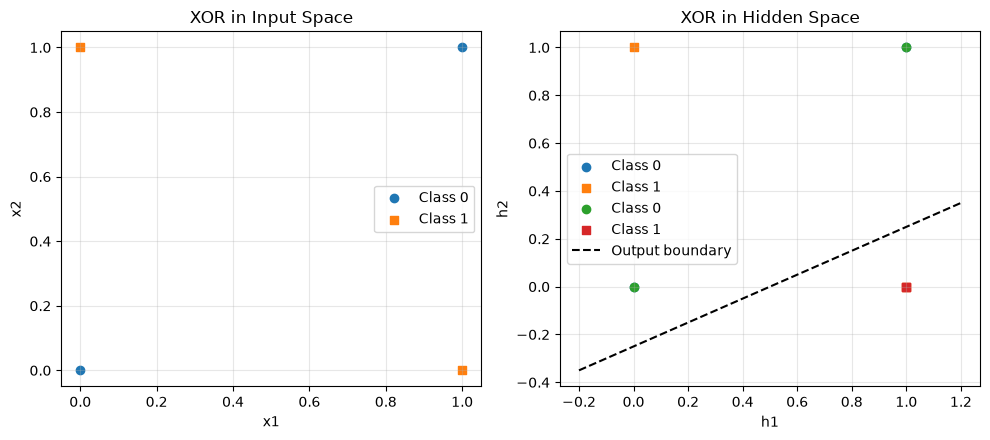

In [5]:
# Task 2.2
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax in axes:
    ax.scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1],
               marker="o", label="Class 0")
    ax.scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1],
               marker="s", label="Class 1")
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[0].set_title("XOR in Input Space")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")

axes[1].scatter(h_xor[y_xor == 0, 0], h_xor[y_xor == 0, 1],
                marker="o", label="Class 0")
axes[1].scatter(h_xor[y_xor == 1, 0], h_xor[y_xor == 1, 1],
                marker="s", label="Class 1")
# h1 - 2*h2 - 0.5 = 0 => h2 = (h1 - 0.5)/2
h1_line = np.linspace(-0.2, 1.2, 100)
h2_line = (h1_line - 0.5) / 2
axes[1].plot(h1_line, h2_line, "k--", label="Output boundary")
axes[1].set_title("XOR in Hidden Space")
axes[1].set_xlabel("h1")
axes[1].set_ylabel("h2")
axes[1].legend()
plt.tight_layout()
plt.show()


**Interpretation:** In input space, XOR has alternating class labels and one straight line cannot separate them. The hidden layer transforms the points into a space where the output boundary can separate the classes.

## Part 3 — Gradient Descent and the Learning Rate

**Task 3.1**: Minimize L(w)=(w−3)² starting at −4 for 30 steps using four learning rates.

eta=0.01: final w=-0.818390, final loss=14.580104
eta=0.1: final w=2.991334, final loss=0.000075
eta=0.9: final w=2.991334, final loss=0.000075
eta=1.05: final w=-119.145816, final loss=14919.600338


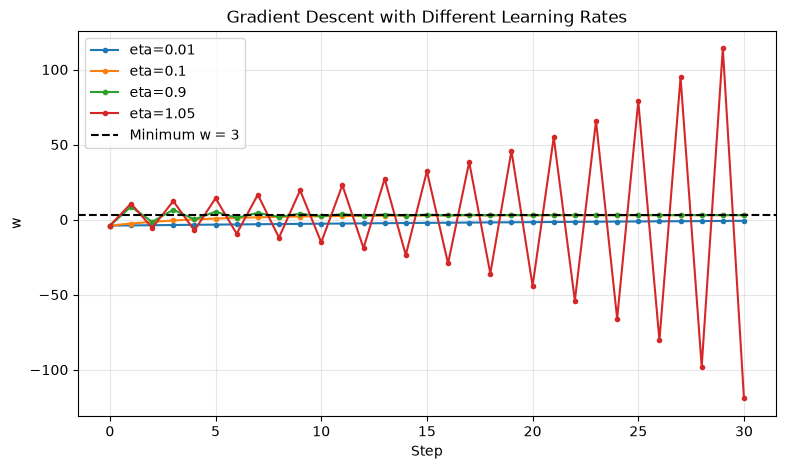

In [6]:
# Task 3.1
def gradient_descent(w0, eta, steps):
    values = [w0]
    w = w0
    for _ in range(steps):
        gradient = 2 * (w - 3)
        w = w - eta * gradient
        values.append(w)
    return values

rates = [0.01, 0.1, 0.9, 1.05]
plt.figure(figsize=(9, 5))
for eta in rates:
    values = gradient_descent(-4, eta, 30)
    plt.plot(range(len(values)), values, marker=".", label=f"eta={eta}")
    print(f"eta={eta}: final w={values[-1]:.6f}, final loss={(values[-1]-3)**2:.6f}")
plt.axhline(3, linestyle="--", color="black", label="Minimum w = 3")
plt.xlabel("Step")
plt.ylabel("w")
plt.title("Gradient Descent with Different Learning Rates")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Interpretation:** `0.01` is slow, `0.1` moves steadily toward the minimum, `0.9` zig-zags while converging, and `1.05` overshoots and diverges because its updates are too large.

## Part 4 — Backpropagation and the Chain Rule

### 4.1 Chain Rule for One Neuron
**Task 4.1**: Calculate the gradient, verify it numerically and perform one update.

In [7]:
# Task 4.1
x = np.array([1.0, 2.0])
w = np.array([0.5, -0.3])
b = 0.1
y = 1.0
eta = 0.5

def neuron_loss(w, b, x, y):
    a = sigmoid(np.dot(w, x) + b)
    return 0.5 * (y - a)**2, a

loss, a = neuron_loss(w, b, x, y)
z = np.dot(w, x) + b
grad_w = -(y - a) * a * (1 - a) * x
grad_b = -(y - a) * a * (1 - a)

eps = 0.0001
numerical_grad = np.array([
    (neuron_loss(w + np.eye(2)[i] * eps, b, x, y)[0] -
     neuron_loss(w - np.eye(2)[i] * eps, b, x, y)[0]) / (2 * eps)
    for i in range(2)
])
print(f"z={z:.6f}, a={a:.6f}, loss={loss:.6f}")
print("Chain-rule gradient w:", grad_w)
print("Chain-rule gradient b:", grad_b)
print("Numerical gradient w:", numerical_grad)
print("Gradient check passed:", np.allclose(grad_w, numerical_grad, atol=1e-5))

new_w = w - eta * grad_w
new_b = b - eta * grad_b
new_loss, new_a = neuron_loss(new_w, new_b, x, y)
print("Updated w:", new_w)
print("Updated b:", new_b)
print(f"Updated loss={new_loss:.6f}, loss decreased={new_loss < loss}")


z=0.000000, a=0.500000, loss=0.125000
Chain-rule gradient w: [-0.125 -0.25 ]
Chain-rule gradient b: -0.125
Numerical gradient w: [-0.125 -0.25 ]
Gradient check passed: True
Updated w: [ 0.5625 -0.175 ]
Updated b: 0.1625
Updated loss=0.082960, loss decreased=True


**Interpretation:** The numerical gradients closely match the chain-rule gradients, validating the calculation. The update moves the weights and bias in a direction that reduces the loss.

### 4.2 Train an MLP on XOR With Backpropagation
**Task 4.2**: Train a 2-4-1 sigmoid network for 5000 epochs using η=0.5.

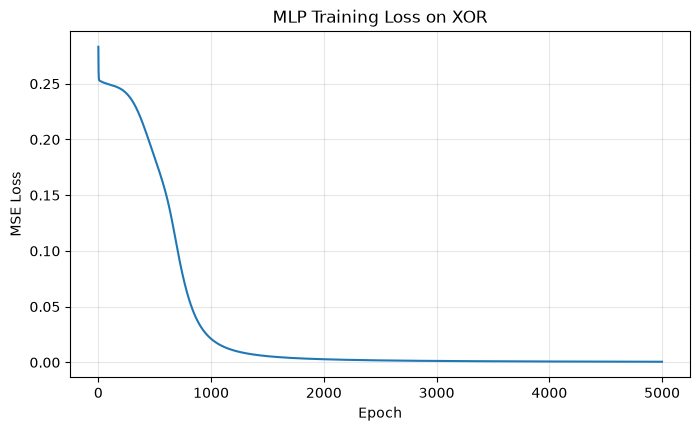

Final outputs:
[0.01644581 0.9785411  0.97472215 0.028438  ]
Rounded predictions: [0 1 1 0]
True labels: [0 1 1 0]
All predictions correct: True


In [8]:
# Task 4.2
np.random.seed(42)
W1 = np.random.randn(2, 4)
b1 = np.zeros(4)
W2 = np.random.randn(4, 1)
b2 = np.zeros(1)
eta = 0.5
epochs = 5000
losses = []

for epoch in range(epochs):
    H = sigmoid(X_xor @ W1 + b1)
    A = sigmoid(H @ W2 + b2)
    loss = np.mean((A - y_xor.reshape(-1, 1))**2)
    losses.append(loss)

    # Calculate every gradient using the original weights, then update.
    dA = (A - y_xor.reshape(-1, 1)) * A * (1 - A)
    dW2 = H.T @ dA
    db2 = dA.sum(axis=0)
    dH = (dA @ W2.T) * H * (1 - H)
    dW1 = X_xor.T @ dH
    db1 = dH.sum(axis=0)

    W1 -= eta * dW1
    b1 -= eta * db1
    W2 -= eta * dW2
    b2 -= eta * db2

H_final = sigmoid(X_xor @ W1 + b1)
A_final = sigmoid(H_final @ W2 + b2)
preds = (A_final >= 0.5).astype(int)
plt.figure(figsize=(8, 4.5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("MLP Training Loss on XOR")
plt.grid(True, alpha=0.3)
plt.show()

print("Final outputs:")
print(A_final.ravel())
print("Rounded predictions:", preds.ravel())
print("True labels:", y_xor)
print("All predictions correct:", np.array_equal(preds.ravel(), y_xor))


**Interpretation:** The loss curve shows how training improves as the network updates its weights. The final rounded predictions are compared with the XOR labels, and the printed Boolean confirms whether the network learned all four cases.

## Part 5 — MLP in Keras on Real Data

**Task 5.1**: Train a 30-16-8-1 sigmoid model on Breast Cancer data, using a stratified 80/20 split and training-only scaling.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,925 (7.52 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,284 (5.02 KB)

Trainable parameters: 641
Test accuracy: 0.9737

Classification report:
               precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



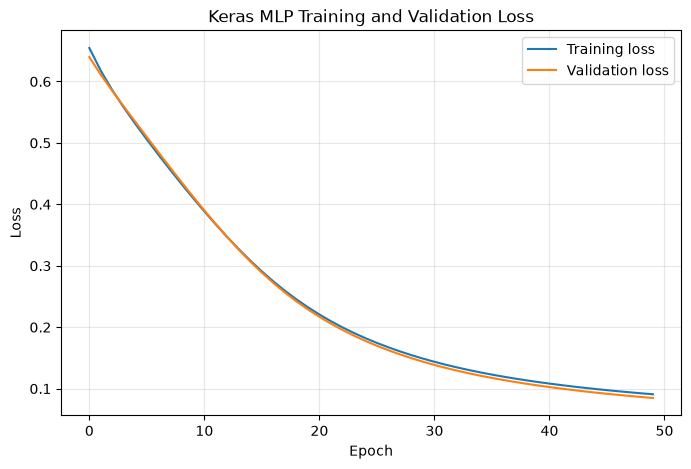

In [9]:
# Task 5.1
cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X_cancer, y_cancer, test_size=0.20, random_state=42, stratify=y_cancer
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(16, activation="sigmoid"),
    keras.layers.Dense(8, activation="sigmoid"),
    keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(
    X_train_scaled, y_train, epochs=50, validation_split=0.2, verbose=0
)

model.summary()
print("Trainable parameters:", model.count_params())
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
y_test_pred = (model.predict(X_test_scaled, verbose=0).ravel() >= 0.5).astype(int)
print(f"Test accuracy: {test_accuracy:.4f}")
print("\nClassification report:\n",
      classification_report(y_test, y_test_pred, target_names=cancer.target_names))

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Keras MLP Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Interpretation:** Test accuracy and the classification report summarize how the trained model performs on unseen data. Training and validation loss curves help identify whether learning improves and whether the model begins overfitting.

## Part 6 — Graded Questions
> Answers and numeric checks are completed below. Review the values from the executed cells before submission.

**Q1 [4 marks]** (a) Show the linear layers can combine. (b) Why replace step with sigmoid?

**Answer:**

**(a)** Start with the two layers:
`W₂(W₁x + b₁) + b₂`

Distribute W₂:
`= W₂W₁x + W₂b₁ + b₂`

So one layer can use `W = W₂W₁` and `b = W₂b₁ + b₂` (using the manual's column-vector convention). Therefore, stacking linear layers without an activation still gives a linear transformation.

**(b)** Step has derivative zero almost everywhere, so gradient descent cannot use it to update weights. Sigmoid is smooth and has a non-zero slope around the middle, so backpropagation can calculate useful gradients.


**Q2 [4 marks]** Forward pass by hand with sigmoid at every layer, then check using the forward function.

In [10]:
# Q2
W1_q2 = np.array([[0.2, 0.4], [0.6, -0.1]])
b1_q2 = np.array([0.0, 0.1])
W2_q2 = np.array([[0.5], [-0.3]])
b2_q2 = np.array([0.2])
x_q2 = np.array([[1.0, 2.0]])

z1_q2 = x_q2 @ W1_q2 + b1_q2
h_q2 = sigmoid(z1_q2)
z2_q2 = h_q2 @ W2_q2 + b2_q2
yhat_q2 = sigmoid(z2_q2)
print("z1 =", z1_q2)
print("h1 =", h_q2)
print("z2 =", z2_q2)
print("yhat =", yhat_q2)
h_check, y_check = forward(x_q2, W1_q2, b1_q2, W2_q2, b2_q2, sigmoid)
print("Forward-function check:", np.allclose(h_check, h_q2) and np.allclose(y_check, yhat_q2))
print("Rounded h1, h2, yhat:", np.round(h_q2, 3), np.round(yhat_q2, 3))


z1 = [[1.4 0.3]]
h1 = [[0.80218389 0.57444252]]
z2 = [[0.42875919]]
yhat = [[0.60557734]]
Forward-function check: True
Rounded h1, h2, yhat: [[0.802 0.574]] [[0.606]]


**Answer:** The code shows the hidden-layer pre-activation values, hidden sigmoid outputs, output pre-activation and final sigmoid prediction. The final check confirms the hand calculation agrees with the forward function.

**Q3 [6 marks]** Backpropagation for the single neuron when y=0, gradient, update, and explanation of η=1.05.

In [11]:
# Q3
x_q3 = np.array([1.0, 2.0])
w_q3 = np.array([0.5, -0.3])
b_q3 = 0.1
y_q3 = 0.0
eta_q3 = 0.5

loss_q3, a_q3 = neuron_loss(w_q3, b_q3, x_q3, y_q3)
grad_w_q3 = -(y_q3 - a_q3) * a_q3 * (1 - a_q3) * x_q3
grad_b_q3 = -(y_q3 - a_q3) * a_q3 * (1 - a_q3)
w_q3_new = w_q3 - eta_q3 * grad_w_q3
b_q3_new = b_q3 - eta_q3 * grad_b_q3
new_loss_q3, new_a_q3 = neuron_loss(w_q3_new, b_q3_new, x_q3, y_q3)

print(f"Initial output={a_q3:.6f}, initial loss={loss_q3:.6f}")
print("Gradient w:", grad_w_q3)
print("Gradient b:", grad_b_q3)
print("Updated w:", w_q3_new)
print("Updated b:", b_q3_new)
print(f"New output={new_a_q3:.6f}, new loss={new_loss_q3:.6f}")
print("Loss decreased:", new_loss_q3 < loss_q3)


Initial output=0.500000, initial loss=0.125000
Gradient w: [0.125 0.25 ]
Gradient b: 0.125
Updated w: [ 0.4375 -0.425 ]
Updated b: 0.037500000000000006
New output=0.407333, new loss=0.082960
Loss decreased: True


**Answer:** The code computes all three gradients and performs the update using η=0.5. A learning rate of 1.05 is too large for this convex example: it overshoots the minimum repeatedly and the values grow instead of settling, because the update is larger than the stable range.


**Q4 [6 marks]** Retrain with one hidden layer of 4, 16 and 64 neurons for 100 epochs, compare parameters and train/test accuracy, and plot validation loss.

Hidden    Parameters  Train acc   Test acc    
4         129         0.9868      0.9737      
16        513         0.9890      0.9649      
64        2049        0.9868      0.9561      


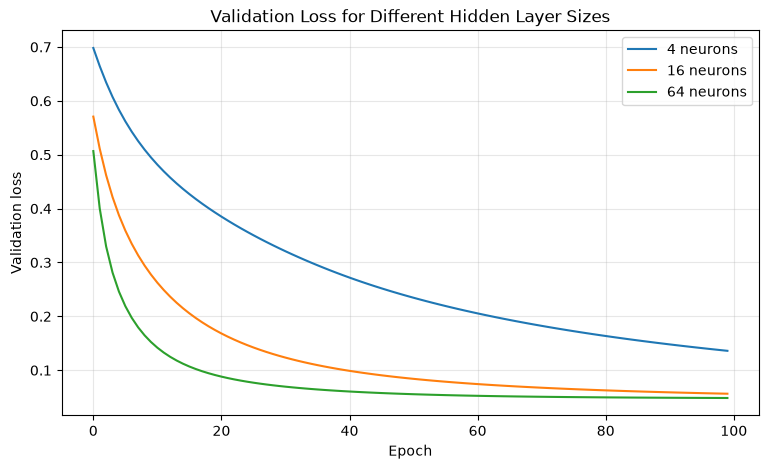

In [12]:
# Q4
hidden_sizes = [4, 16, 64]
size_results = []
size_histories = {}

for size in hidden_sizes:
    tf.keras.utils.set_random_seed(42)
    size_model = keras.Sequential([
        keras.Input(shape=(30,)),
        keras.layers.Dense(size, activation="sigmoid"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    size_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    size_history = size_model.fit(
        X_train_scaled, y_train, epochs=100, validation_split=0.2, verbose=0
    )
    train_loss, train_acc = size_model.evaluate(X_train_scaled, y_train, verbose=0)
    test_loss_size, test_acc = size_model.evaluate(X_test_scaled, y_test, verbose=0)
    size_results.append({
        "hidden_neurons": size,
        "parameters": size_model.count_params(),
        "train_accuracy": train_acc,
        "test_accuracy": test_acc,
    })
    size_histories[size] = size_history

print(f"{'Hidden':<10}{'Parameters':<12}{'Train acc':<12}{'Test acc':<12}")
for item in size_results:
    print(f"{item['hidden_neurons']:<10}{item['parameters']:<12}"
          f"{item['train_accuracy']:<12.4f}{item['test_accuracy']:<12.4f}")

plt.figure(figsize=(9, 5))
for size in hidden_sizes:
    plt.plot(size_histories[size].history["val_loss"], label=f"{size} neurons")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Validation Loss for Different Hidden Layer Sizes")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Analysis:** Compare the train and test accuracy table with the three validation-loss curves. Prefer the smallest network that achieves strong test accuracy and stable validation loss; a large gap between training and validation performance or validation loss rising while training loss falls suggests overfitting. The actual choice should be based on the output of this run.